# Exploratory analysis of the Kaggle dataset

This notebook describes the [Traffic Prediction Dataset](https://www.kaggle.com/datasets/fedesoriano/traffic-prediction-dataset): hourly vehicle counts from four junctions. It looks only at the data. How well the generator fits this data is covered in `layer1_model_fit.ipynb`.

Run `uv run python scripts/download_kaggle_data.py` first to get the data.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import MSTL

DATA_PATH = Path("../data/raw/kaggle_traffic.csv")

plt.rcParams.update(
    {
        "figure.figsize": (12, 4),
        "figure.dpi": 90,
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c3c2b7",
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]),
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.8,
        "legend.frameon": False,
    }
)

## 1. Data read & quality control

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["DateTime"])
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 48120 entries, 0 to 48119
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   DateTime  48120 non-null  datetime64[us]
 1   Junction  48120 non-null  int64         
 2   Vehicles  48120 non-null  int64         
 3   ID        48120 non-null  int64         
dtypes: datetime64[us](1), int64(3)
memory usage: 1.5 MB


,DateTime,Junction,Vehicles,ID
0,2015-11-01 00:00:00,1,15,20151101001
1,2015-11-01 01:00:00,1,13,20151101011
2,2015-11-01 02:00:00,1,10,20151101021
3,2015-11-01 03:00:00,1,7,20151101031
4,2015-11-01 04:00:00,1,9,20151101041


In [3]:
# Timespan and number of observations per junction
df.groupby("Junction")["DateTime"].agg(["min", "max", "count"])

,min,max,count
Junction,,,
1,2015-11-01,2017-06-30 23:00:00,14592
2,2015-11-01,2017-06-30 23:00:00,14592
3,2015-11-01,2017-06-30 23:00:00,14592
4,2017-01-01,2017-06-30 23:00:00,4344


In [4]:
print("Duplicates:", df.duplicated(subset=["DateTime", "Junction"]).sum())
print("NaN:", df["Vehicles"].isna().sum())
df["Vehicles"].describe()

Duplicates: 0
NaN: 0


count    48120.000000
mean        22.791334
std         20.750063
min          1.000000
25%          9.000000
50%         15.000000
75%         29.000000
max        180.000000
Name: Vehicles, dtype: float64

In [5]:
wide = df.pivot_table(index="DateTime", columns="Junction", values="Vehicles", aggfunc="mean")
wide.columns = [f"J{c}" for c in wide.columns]
full_index = pd.date_range(wide.index.min(), wide.index.max(), freq="h")
wide = wide.reindex(full_index).rename_axis("DateTime")

# Missing data inside the range for each junction
for col in wide.columns:
    s = wide[col].dropna()
    inside = wide[col].loc[s.index.min():s.index.max()]
    print(col, "missing:", inside.isna().sum())

J1 missing: 0
J2 missing: 0
J3 missing: 0
J4 missing: 0


In [6]:
# Number of continuous gaps (in hours) for each junction
for col in wide.columns:
    s = wide[col].dropna()
    inside = wide[col].loc[s.index.min():s.index.max()]
    gap_id = inside.notna().cumsum()
    gaps = inside[inside.isna()].groupby(gap_id[inside.isna()]).size()
    print(col, "number of gaps:", len(gaps), "longest:", gaps.max() if len(gaps) else 0)

J1 number of gaps: 0 longest: 0
J2 number of gaps: 0 longest: 0
J3 number of gaps: 0 longest: 0
J4 number of gaps: 0 longest: 0


## 2. Visualizations

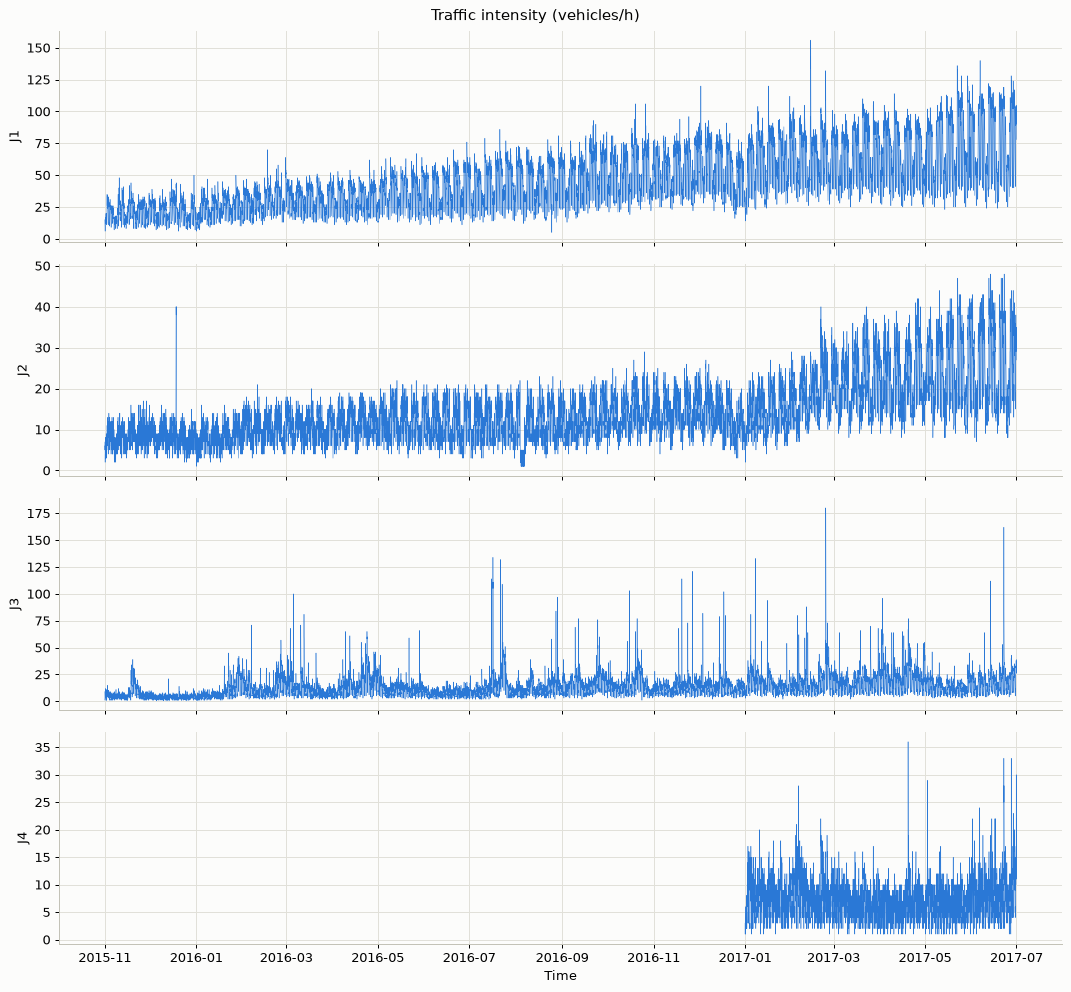

In [7]:
fig, axes = plt.subplots(len(wide.columns), 1, figsize=(12, 2.8 * len(wide.columns)), sharex=True)
for ax, col in zip(axes, wide.columns, strict=True):
    ax.plot(wide.index, wide[col], lw=0.4)
    ax.set_ylabel(col)
axes[-1].set_xlabel("Time")
fig.suptitle("Traffic intensity (vehicles/h)")
plt.tight_layout()
plt.show()

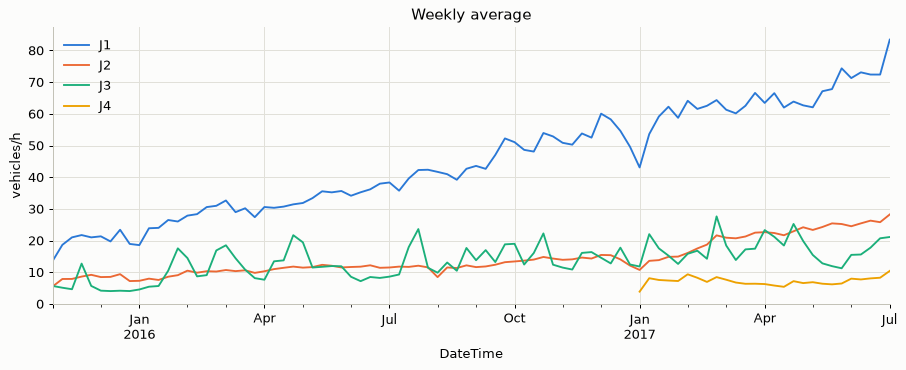

In [8]:
wide.resample("W").mean().plot(figsize=(12, 4), title="Weekly average", ylabel="vehicles/h")
plt.show()

In [9]:
# Volume in March to June of each year: the same months, to rule out the time of year.
spring = {year: wide.loc[f"{year}-03":f"{year}-06"].mean() for year in (2016, 2017)}
(spring[2017] / spring[2016]).dropna().round(2)

J1    2.03
J2    2.09
J3    1.45
dtype: float64

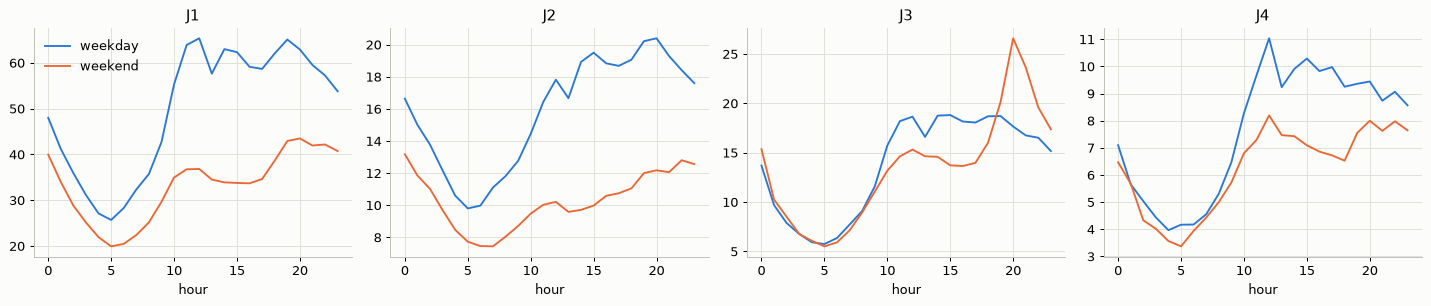

In [10]:
tmp = wide.copy()
tmp["hour"] = tmp.index.hour
tmp["weekend"] = tmp.index.day_of_week >= 5

fig, axes = plt.subplots(1, len(wide.columns), figsize=(4 * len(wide.columns), 3.5))
for ax, col in zip(axes, wide.columns, strict=True):
    for label, g in tmp.groupby("weekend"):
        ax.plot(g.groupby("hour")[col].mean(), label="weekend" if label else "weekday")
    ax.set_title(col)
    ax.set_xlabel("hour")
axes[0].legend()
plt.tight_layout()
plt.show()

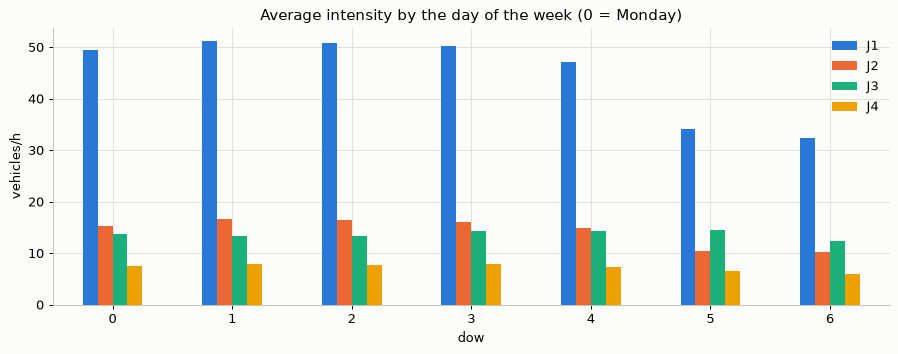

In [11]:
tmp["dow"] = tmp.index.day_of_week
tmp.groupby("dow")[list(wide.columns)].mean().plot(
    kind="bar",
    title="Average intensity by the day of the week (0 = Monday)",
    ylabel="vehicles/h",
    rot=0,
)
plt.show()

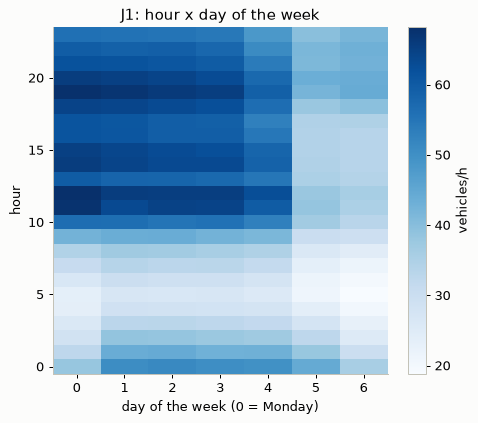

In [12]:
col = "J1"
pivot = tmp.pivot_table(index="hour", columns="dow", values=col, aggfunc="mean")
plt.figure(figsize=(6, 5))
plt.imshow(pivot, aspect="auto", origin="lower", cmap="Blues")
plt.colorbar(label="vehicles/h")
plt.grid(False)
plt.xlabel("day of the week (0 = Monday)")
plt.ylabel("hour")
plt.title(f"{col}: hour x day of the week")
plt.show()

## 3. Seasonality and autocorrelation

The decomposition below separates a daily and a weekly cycle from the long-term trend.

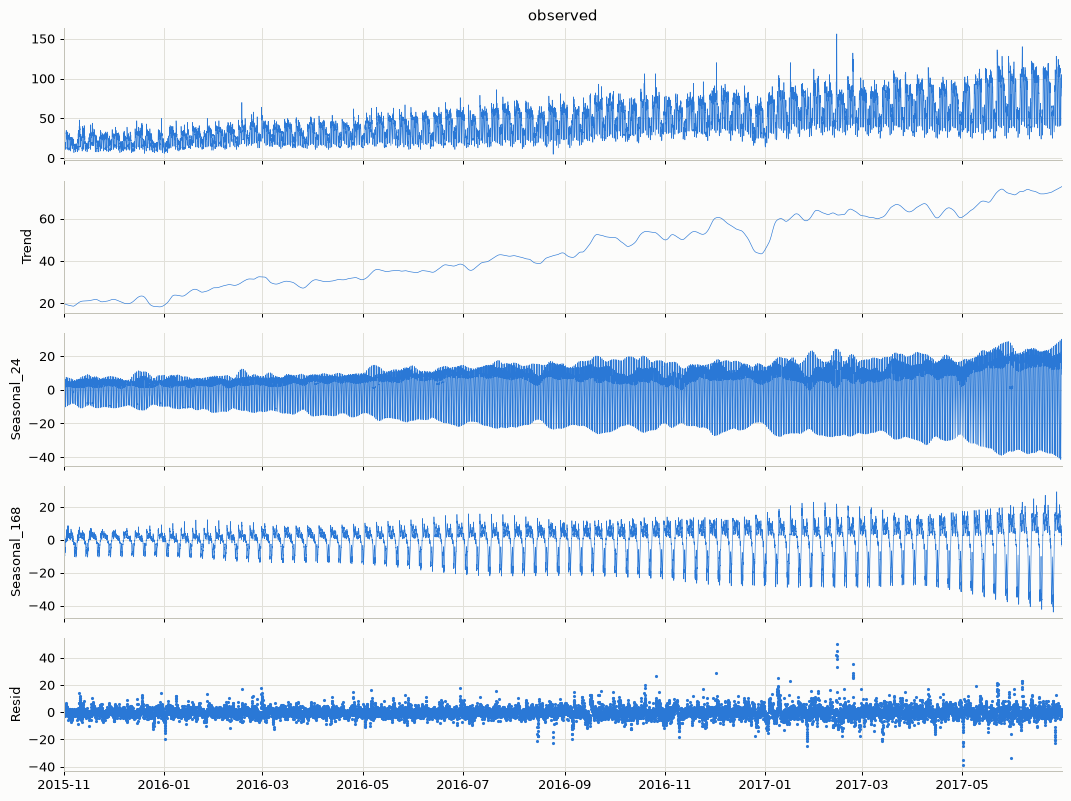

In [13]:
col = "J1"
series = wide[col].dropna()
res = MSTL(series, periods=(24, 24 * 7)).fit()
figure = res.plot()
figure.set_size_inches(12, 9)
for axis in figure.axes:
    for line in axis.get_lines():
        line.set_markersize(1.5)
        line.set_linewidth(0.5)
plt.tight_layout()
plt.show()

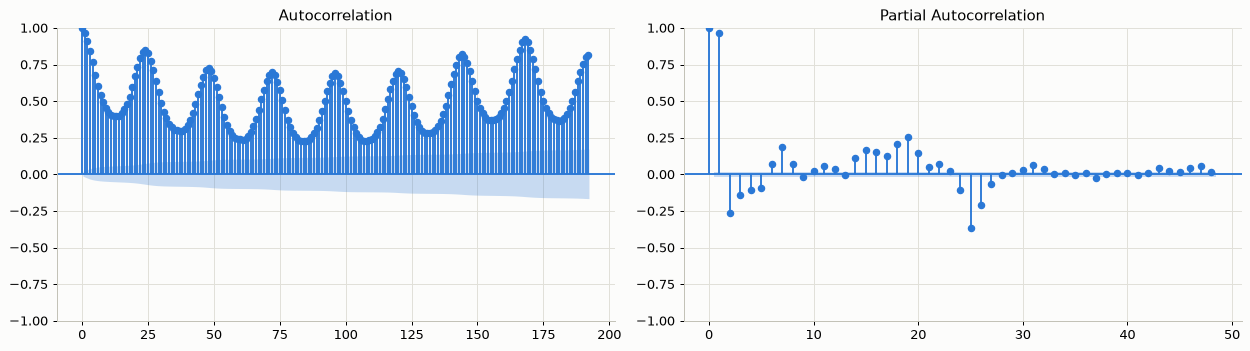

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(series, lags=24 * 8, ax=axes[0])
plot_pacf(series, lags=48, ax=axes[1])
plt.tight_layout()
plt.show()

In [15]:
pd.DataFrame(
    {col: [wide[col].autocorr(lag) for lag in (1, 24, 24 * 7)] for col in wide.columns},
    index=["1 hour", "1 day", "1 week"],
).round(2)

,J1,J2,J3,J4
1 hour,0.96,0.92,0.84,0.63
1 day,0.85,0.81,0.58,0.47
1 week,0.95,0.89,0.45,0.45


## 4. Junctions comparison

In [16]:
wide.describe().T

,count,mean,std,min,25%,50%,75%,max
J1,14592.0,45.052906,23.008345,5.0,27.0,40.0,59.0,156.0
J2,14592.0,14.253221,7.401307,1.0,9.0,13.0,17.0,48.0
J3,14592.0,13.694010,10.436005,1.0,7.0,11.0,18.0,180.0
J4,4344.0,7.251611,3.521455,1.0,5.0,7.0,9.0,36.0


In [17]:
# Only hours where all junctions have data: J4 limits this to the first half of 2017.
wide.dropna().corr()

,J1,J2,J3,J4
J1,1.000000,0.827574,0.514610,0.592566
J2,0.827574,1.000000,0.378791,0.396314
J3,0.514610,0.378791,1.000000,0.485609
J4,0.592566,0.396314,0.485609,1.000000


In [18]:
wide.quantile([0.05, 0.5, 0.95, 0.99]).T

,0.05,0.50,0.95,0.99
J1,15.0,40.0,89.0,108.09
J2,6.0,13.0,30.0,38.00
J3,3.0,11.0,30.0,51.00
J4,2.0,7.0,13.0,18.00


## 5. Findings

- **Quality:** there are no duplicates, missing values or gaps inside each junction's period. No cleaning is needed.
- **Coverage:** J1 to J3 cover November 2015 to June 2017, while J4 only covers the first half of 2017.
- **Growth:** volume rises strongly over time, roughly doubling on J1 and J2 from spring 2016 to spring 2017. With less than two years of data, growth cannot be separated from the time of year.
- **Daily and weekly cycles:** all junctions are quiet in the early morning. J1 and J2 are much quieter on weekends, while the weekend effect is smaller on J3 and J4.
- **J3 on weekends:** J3 has a sharp evening peak on weekends, around 20:00. J1 and J2 rise far less at that time, and J4 does not rise.
- **Size of the cycles:** on J1, the daily and weekly swings widen as volume grows, so the cycles act more like multipliers than fixed amounts.
- **Autocorrelation:** on J1 it peaks at multiples of 24 hours and most strongly at one week (0.95), which confirms both cycles. This differs per junction: on J3, the correlation at one week (0.45) is below the one at one day (0.58).
- **Bursts:** J3 has large outliers, with a maximum of 180 vehicles per hour against a 99th percentile of 51.
- **Junctions:** raw correlations are high for J1 and J2 (0.83 in the first half of 2017, the only period all four junctions share), but much of this may come from sharing daily and weekly cycles. The dataset has no information on how the junctions are connected, or on directions, lanes or vehicle types.